<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🗺️ 全景地图 · 新旧 API 对照 · 复习清单

**一句话定位**：复习从这里开始——一张图看全部概念，一张表看课件里哪些写法已过时，一份清单自测掌握程度。

</div>

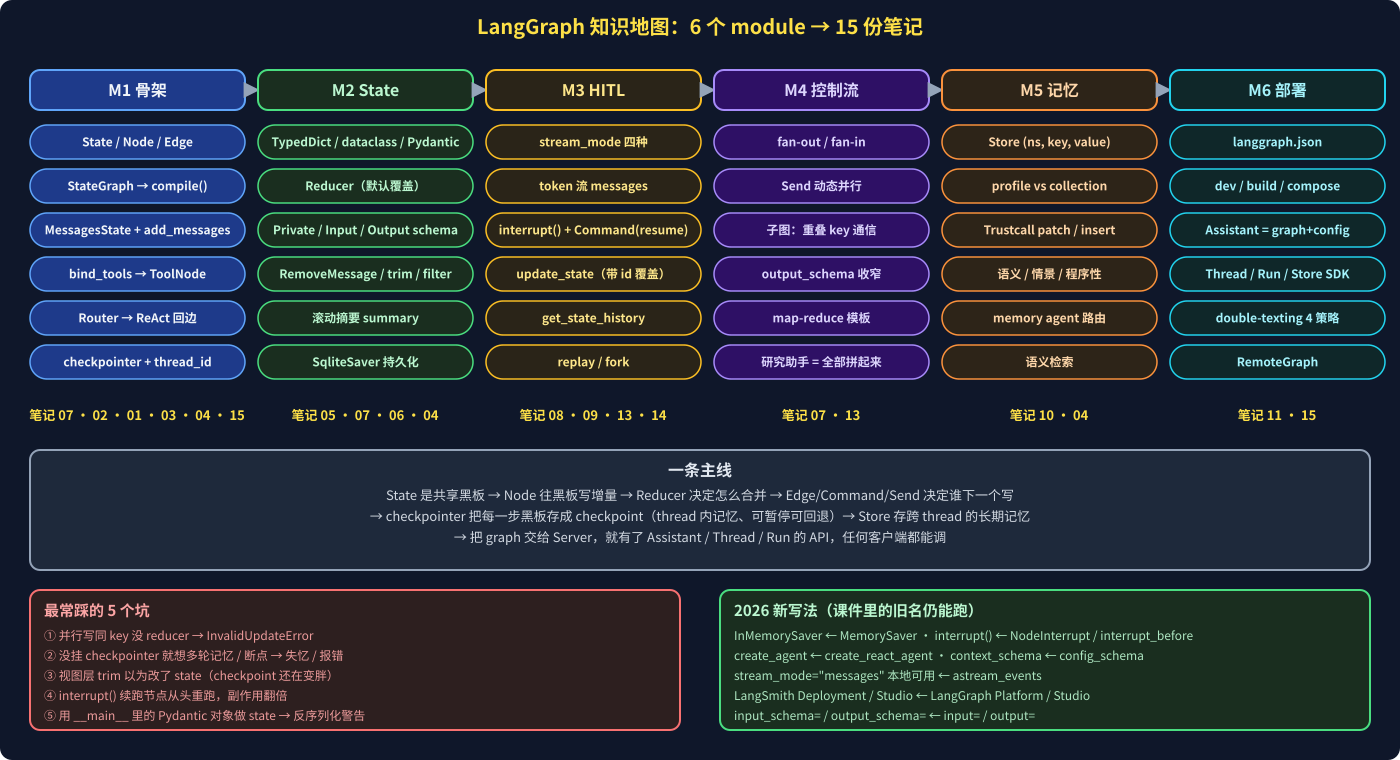

In [ ]:
from IPython.display import SVG
SVG(filename="assets/12_knowledge_map.svg")

### 1️⃣ 笔记索引（按复习顺序）

| # | 主题 | 一句话 |
|---|---|---|
| 07 | Graph API 与控制流 | State/Node/Edge，super-step，条件边 vs Command vs Send，并行、子图、map-reduce |
| 13 | **Command** | update / goto / resume / graph 四字段；节点、工具、invoke 输入三处用法；goto 不取消静态边 |
| 05 | Reducer | 增量如何合并：默认覆盖、`add`、`add_messages`、`Overwrite`、自定义 |
| 02 | Message | 五种消息、四种写法、tool_call ↔ ToolMessage 配对、管理函数 |
| 01 | Tool | `@tool` / 普通函数 / `BaseTool`，docstring 即说明书，`bind_tools` 只传说明书 |
| 03 | ReAct Agent | 手写循环 vs `create_agent` 一行 |
| 15 | **thread_id / checkpointer / Store / Server** | 钥匙 vs 箱子 vs 仓库：有效期 = 存储寿命；多进程同 thread；Server 的 thread 规则；库/CLI/Server/SDK 对照 |
| 04 | Memory 基础 | checkpointer + thread_id（短期）、Store + namespace（长期） |
| 06 | 长对话管理 | trim / filter / RemoveMessage / 摘要 / 中间件 / 计费 |
| 08 | Streaming | values / updates / messages / custom，本地与 SDK 对照 |
| 09 | HITL & Time travel | interrupt + Command(resume)，update_state，history / replay / fork |
| 14 | Slack 人工审批 | notify 节点发按钮 → `interrupt()` → Bolt 回调 → `Command(resume)`；拆节点、3 秒 ack、判重 |
| 10 | 长期记忆进阶 | Store 语义检索、profile vs collection、Trustcall、memory agent |
| 11 | 部署 | langgraph.json、Server 架构、SDK 四对象、Assistant、double-texting、RemoteGraph |

### 2️⃣ 课件 → 2026 现行写法对照（均已在本机 langgraph 1.2 / langchain 1.3 验证）

| 课件写法 | 现行写法 | 状态 |
|---|---|---|
| `MemorySaver()` | `InMemorySaver()` | 别名，可跑 |
| `raise NodeInterrupt(msg)` | `answer = interrupt(payload)` + `Command(resume=…)` | 1.0 弃用，2.0 移除 |
| `interrupt_before=["node"]` 做审批 | `interrupt()` | 仍可用，官方定位为调试 |
| 空节点 + `update_state(as_node=…)` 收人工输入 | `interrupt()` 返回值 | 仍可用 |
| 手写 assistant + ToolNode + tools_condition | `langchain.agents.create_agent(model, tools, system_prompt=)` | 手写用于学原理 |
| `langgraph.prebuilt.create_react_agent` | `create_agent` | deprecated |
| `StateGraph(S, input=In, output=Out)` | `StateGraph(S, input_schema=In, output_schema=Out)` | 旧参数弃用 |
| `config_schema=` / `config["configurable"]` 读运行时参数 | `context_schema=` + `runtime.context` | 旧的仍兼容 |
| "`messages` 流模式只有 API 支持" | 本地 `graph.stream(..., stream_mode="messages")` 可用 | 过时说法 |
| `astream_events(version="v2")` 取 token | `stream_mode="messages"`（简单）；`stream_events(version="v3")`（1.2 beta） | 仍可用 |
| 返回 `[]` 想清空带 reducer 的 list | `Overwrite([])` | 新增 |
| `ChatOpenAI(model=…)` 固定厂商 | `init_chat_model("openai:gpt-4o")` | 两者皆可 |
| LangGraph Platform / Cloud / Studio | LangSmith Deployment / LangSmith Studio | 仅改名 |
| state 里放 `__main__` 的 Pydantic 对象 | 注册 `allowed_msgpack_modules` 或存 dict | 未来会拒绝 |

### 3️⃣ 核心概念一页纸

| 概念 | 一句话 | 关键 API |
|---|---|---|
| State | 图内共享数据，每个 key 一个 channel | `TypedDict` / `MessagesState` |
| Reducer | 增量如何并入旧值；无则覆盖 | `Annotated[list, add]` / `add_messages` |
| Node | 读 state、返回增量或 `Command` | `add_node` |
| Edge | 固定 / 条件 / 动态（Command）/ 扇出（Send） | `add_edge` / `add_conditional_edges` |
| Super-step | 一轮并行执行 + 合并 + checkpoint | — |
| Checkpointer | 每步存 state，按 `thread_id` 分会话 | `compile(checkpointer=)` |
| Store | 跨 thread 的 `(namespace, key, value)` | `compile(store=)` / `store.put/search` |
| Interrupt | 节点内暂停，`Command(resume)` 续跑 | `interrupt()` |
| Command | 一个对象：改 state + 选下一跳 + 续跑 + 跳父图 | `Command(update=, goto=, resume=, graph=)` |
| Time travel | 历史 checkpoint 重放 / 分叉 | `get_state_history` / `update_state` |
| Streaming | 按模式流出 state / token / 自定义 | `stream(stream_mode=)` |
| Subgraph | 嵌套 graph，重叠 key 或函数包裹通信 | `add_node(sub.compile())` |
| Send | 运行时按数据展开 N 个并行任务 | `Send(node, state)` |
| Tool | name + description + schema，LLM 只读这三样 | `@tool` / `bind_tools` / `ToolNode` |
| Assistant | 部署后的 graph + config | `client.assistants.create` |
| Thread / Run | 持久会话 / 一次执行 | `client.threads` / `client.runs` |

### 4️⃣ 自测清单（不看笔记能写出来才算过）

- [ ] 从零写一个 3 节点 + 条件边的 `StateGraph`，并解释 `invoke` 返回的是什么
- [ ] 说出 `return {"foo": [x]}` 在有 / 无 reducer 时分别发生什么；并行写同 key 为何报错
- [ ] 手写 ReAct 循环（assistant ↔ tools），再用 `create_agent` 写一遍
- [ ] 给 agent 加记忆：`checkpointer` + `thread_id`；解释为什么没它会"失忆"
- [ ] 用 `RemoveMessage` / `trim_messages` / 滚动摘要三种方式控制长对话，说出谁改 state 谁不改
- [ ] 用 `stream_mode="messages"` 做逐 token 输出并按节点过滤
- [ ] 用 `interrupt()` 实现工具调用审批（approve / edit / reject 三分支），说出续跑规则
- [ ] 写一个节点用 `Command(update=…, goto=…)` 代替条件边，并说出 `goto` 与静态边同时存在会怎样
- [ ] 写一个返回 `Command` 的工具，并说出为什么必须带 `ToolMessage`；子图里如何用 `Command.PARENT` 跳出
- [ ] 用 `get_state_history` 找到某步、重放它、再分叉出不同输入
- [ ] 用 `Send` 写 map-reduce；解释子图并行为何要 `output_schema`
- [ ] 设计 Store 的 namespace，用 Trustcall 更新 profile 与 collection，解释 `json_doc_id`
- [ ] 写出 `langgraph.json`，用 SDK 创建两个 assistant、一个 thread、一次流式 run
- [ ] 说出 double-texting 四策略的区别

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：LangGraph 就一条主线——**State 黑板 → Node 写增量 → Reducer 合并 → Edge 决定下一个 → checkpointer 存每一步（可暂停可回退）→ Store 存跨会话记忆 → Server 把它变成 Assistant/Thread/Run 的 API**。其余都是这条主线上的细节。

</div>